# 08 — Probabilistic forecast: P10 / P50 / P90 bands

**Question:** notebooks 03-07 give one number per hour. A grid operator also needs to know *how sure* that number is: "tomorrow at 18:00 demand will most likely be 22,400 MW, and there is a 1-in-10 chance it goes above 23,300 MW." This notebook builds such ranges for every hour of 2025 and checks whether they can be trusted.

**Setup:** the same features and midnight forecast cutoff as notebooks 03-06 (`cutoff_hour=0`), the same split (train 2019-2023, validate 2024, test 2025), and the same LightGBM settings. Only the training goal changes: instead of the average, each model learns one *quantile* of demand.

**Short answer:** quantile models alone are far too confident on new years: their 80% band holds only about 65% of 2025 hours. A simple correction measured on 2024 brings the 2025 coverage to 80%, but the band still misses the highest summer peaks.

**Terms used here**

- **Quantile / P10, P50, P90:** P90 is the value that actual demand should stay *below* 90% of the time; P10 the value it should stay *above* 90% of the time; P50 is the middle (median) forecast. Together, P10 and P90 make an **80% band**: in a well-made forecast, 80% of hours fall inside it, 10% below and 10% above.
- **Quantile regression:** a model trained to predict a quantile instead of the average. LightGBM does this with `objective="quantile"`. We train three separate models, one each for P10, P50 and P90.
- **Coverage:** the share of hours where actual demand landed inside the band. The target here is 80%.
- **Pinball loss:** the standard score for a quantile forecast (lower is better). For P90, being too low costs 9 times more than being too high, so the score pushes the model toward the right quantile, not just toward a small error. For P50 it is half the absolute error.
- **Quantile crossing:** because the three models are trained separately, P10 can come out above P50 or P90 for a few hours. We fix this by sorting the three values in each hour.
- **Conformal calibration (CQR, conformalized quantile regression):** take a year the models did *not* train on (2024), measure how far actual demand fell outside each edge of the band, and move each edge by the amount that would have given exactly 10% misses on that side. It makes no assumption about the shape of the errors.
- **MAPE:** average miss in % of actual demand (notebook 02).

## 1. Data, features and split

The same pipeline as notebook 03: `make_features()` builds the 20 inputs known at midnight before the forecast day, and the years are split into train, validation and test. The new helpers for scoring and calibrating bands live in `src/intervals.py` (with unit tests in `tests/test_intervals.py`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from src.data import build_dataset
from src.features import make_features, FEATURES
from src.intervals import pinball_loss, fix_crossing, interval_report, conformal_offsets, apply_offsets

d = make_features(build_dataset())          # midnight cutoff, same features as notebooks 03-06
train, valid, test = d.loc[:"2023"], d.loc["2024"], d.loc["2025"]
train_full = d.loc[:"2024"]
y_valid, y_test = valid["demand_mw"], test["demand_mw"]
params = dict(learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, verbose=-1, random_state=42)
QUANTILES = [0.1, 0.5, 0.9]
print(len(train), len(valid), len(test))

43656 8784 8760


The row counts match notebook 03: **43,656** training hours, **8,784** validation hours (2024) and **8,760** test hours (2025).

## 2. Train the three quantile models and look at 2024

Each model is trained on 2019-2023, and early stopping on 2024 chooses its number of trees, now judged by pinball loss for that quantile. Then we score the raw band on 2024, the year these models have not trained on. (The warning about `eval_set` is a harmless notice about a renamed LightGBM argument.)

In [2]:
models, best_iter = {}, {}
for a in QUANTILES:
    m = lgb.LGBMRegressor(objective="quantile", alpha=a, n_estimators=3000, **params)
    m.fit(train[FEATURES], train["demand_mw"], eval_set=[(valid[FEATURES], y_valid)],
          eval_metric="quantile", callbacks=[lgb.early_stopping(100, verbose=False)])
    models[a], best_iter[a] = m, m.best_iteration_
print("trees chosen by early stopping:", best_iter)

def predict(ms, X):
    raw = [ms[a].predict(X) for a in QUANTILES]
    crossed = np.mean((raw[0] > raw[1]) | (raw[1] > raw[2]))
    return fix_crossing(*raw), crossed

(v10, v50, v90), crossed = predict(models, valid[FEATURES])
print(f"hours where the raw quantiles cross (2024): {crossed:.1%}")
interval_report(y_valid, v10, v90).round(1)

/usr/local/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/usr/local/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


/usr/local/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


trees chosen by early stopping: {0.1: 2975, 0.5: 1497, 0.9: 250}


hours where the raw quantiles cross (2024): 3.9%


Coverage (%)        63.9
Below P10 (%)        9.2
Above P90 (%)       26.9
Mean width (MW)    965.4
dtype: float64

**What this shows**

- Early stopping chose very different model sizes: **2,975 trees for P10, 1,497 for P50, only 250 for P90**. The P90 model starts getting worse on 2024 very early, a first sign that 2024 looks different from the training years at the top end.
- The raw quantiles cross in **3.9%** of 2024 hours; sorting fixes this.
- The raw 80% band holds only **63.9%** of 2024 hours. The misses are lopsided: **9.2%** below P10 (close to the 10% target) but **26.9%** above P90 (almost three times the target). The band (965 MW wide on average) is placed too low, not just too narrow.
- This is the load-growth problem from notebook 05 again: demand in 2024 and 2025 is higher than in the training years, and tree models cannot forecast above the levels they have seen.

## 3. Calibrate the band on 2024

Conformal calibration: from the 2024 misses, find how much to move P10 and P90 so that, on 2024, 10% of hours fall below P10 and 10% above P90. Positive means the edge moves up.

In [3]:
offsets = conformal_offsets(y_valid, v10, v90, tail=0.10)
print(f"move P10 by {-offsets[0]:+.0f} MW, move P90 by {offsets[1]:+.0f} MW")

move P10 by +19 MW, move P90 by +331 MW


P10 moves up by only **19 MW**, while P90 moves up by **331 MW**. The correction is almost all on the upper side, which matches the 2024 picture: the lower edge was about right, the upper edge too low.

## 4. Test on 2025

Two versions, both scored once on 2025:

- **(a) Raw quantiles:** refit on 2019-2024 with 10% more trees (as notebook 03 does for its final model), no correction.
- **(b) Calibrated:** the models trained on 2019-2023, with the 2024 offsets applied. These models cannot be refitted on 2024, because 2024 is the year used to measure the correction; otherwise the correction would be measured on data the models had already seen.

The table is saved to `results/quantile_2025.csv`.

In [4]:
# (a) raw: refit on 2019-2024 with 10% more trees (as in notebook 03), no calibration
refit = {a: lgb.LGBMRegressor(objective="quantile", alpha=a, n_estimators=int(best_iter[a] * 1.1), **params)
            .fit(train_full[FEATURES], train_full["demand_mw"]) for a in QUANTILES}
(r10, r50, r90), _ = predict(refit, test[FEATURES])
# (b) calibrated: models trained on 2019-2023, band corrected with the 2024 offsets
(c10, c50, c90), _ = predict(models, test[FEATURES])
c10, c90 = apply_offsets(c10, c90, offsets)

def score(p10, p50, p90):
    s = interval_report(y_test, p10, p90)
    s["Pinball P10"] = pinball_loss(y_test, p10, 0.1)
    s["Pinball P50"] = pinball_loss(y_test, p50, 0.5)
    s["Pinball P90"] = pinball_loss(y_test, p90, 0.9)
    s["P50 MAPE (%)"] = (np.abs(p50 - y_test) / y_test).mean() * 100
    return s

table = pd.DataFrame({"Raw quantiles (refit 2019-2024)": score(r10, r50, r90),
                      "Calibrated on 2024 (conformal)": score(c10, c50, c90)}).T.round(2)
table.to_csv("results/quantile_2025.csv")
table

,Coverage (%),Below P10 (%),Above P90 (%),Mean width (MW),Pinball P10,Pinball P50,Pinball P90,P50 MAPE (%)
Raw quantiles (refit 2019-2024),64.84,6.82,28.34,975.81,82.08,220.08,126.84,2.59
Calibrated on 2024 (conformal),80.11,6.02,13.87,1319.74,87.41,253.44,107.13,2.97


**What the table means**

- **Raw quantiles are over-confident.** Only **64.8%** of 2025 hours fall inside the raw band, and **28.3%** are above P90 instead of 10%. Adding 2024 to the training data did not fix this, because 2025 demand rose again (notebook 05).
- **The calibrated band works on average: 80.1% coverage** in 2025, the year it never saw. The misses are still lopsided (**6.0%** below, **13.9%** above), but much closer to 10/10. The price is a wider band: **1,320 MW** on average instead of 976 MW.
- **Pinball loss shows the trade-off.** Calibration improves the P90 score (126.8 → 107.1) but the P10 and P50 scores get worse (82.1 → 87.4 and 220.1 → 253.4), because the calibrated version uses models that never saw 2024. For the same reason its median forecast has **2.97% MAPE**, against **2.59%** for the refitted median (slightly better than the 2.63% of the average-based model in notebooks 03 and 07).
- In practice: use the refitted P50 as the point forecast, and the calibrated band when the risk of a high-demand hour matters.

## 5. Is the band reliable in every month?

An 80% band that is right on average can still be wrong in some seasons. We compute coverage for each month of 2025, for the raw and the calibrated band, plus the calibrated band's average width.

datetime,1,2,3,4,5,6,7,8,9,10,11,12
raw,60.3,66.8,64.0,63.7,74.1,64.3,59.8,66.0,71.9,63.3,66.5,57.7
calibrated,74.9,82.6,74.7,80.3,92.9,77.4,73.9,73.4,89.3,84.4,86.9,71.4
width_mw,1148.9,1333.0,1393.1,1326.0,1230.9,1454.9,1586.7,1468.5,1249.5,1183.7,1200.8,1260.8


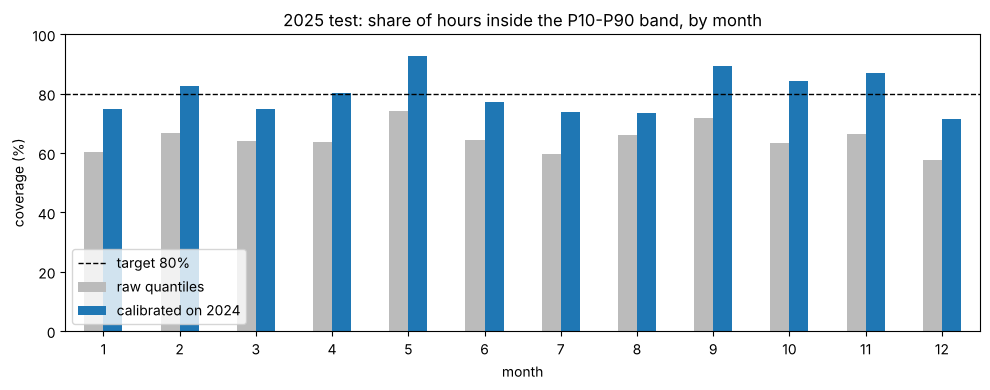

In [5]:
band = pd.DataFrame({"y": y_test, "p10": c10, "p50": c50, "p90": c90,
                     "raw10": r10, "raw90": r90}, index=y_test.index)
band["inside"] = (band.y >= band.p10) & (band.y <= band.p90)
band["inside_raw"] = (band.y >= band.raw10) & (band.y <= band.raw90)
band["width"] = band.p90 - band.p10
by_month = band.groupby(band.index.month).agg(raw=("inside_raw", "mean"), calibrated=("inside", "mean"),
                                               width_mw=("width", "mean"))
by_month[["raw", "calibrated"]] *= 100

fig, ax = plt.subplots(figsize=(10, 4))
by_month[["raw", "calibrated"]].rename(columns={"raw": "raw quantiles", "calibrated": "calibrated on 2024"}).plot(
    kind="bar", ax=ax, color=["#bbbbbb", "#1f77b4"], rot=0)
ax.axhline(80, color="black", ls="--", lw=1, label="target 80%")
ax.set(title="2025 test: share of hours inside the P10-P90 band, by month", ylabel="coverage (%)",
       xlabel="month", ylim=(0, 100))
ax.legend(loc="lower left")
fig.tight_layout(); fig.savefig("figures/quantile_coverage_by_month_2025.png", dpi=130)
by_month.round(1).T

**What the figure shows**

- The raw band is below target in every month (57.7% in December to 74.1% in May).
- After calibration, coverage ranges from **71.4% (December)** to **92.9% (May)**. It is furthest below target in **December, August, July, March and January (71-75%)**, mostly months with heavy heating or cooling load, and over target in the mild months (May 92.9%, September 89.3%).
- The band is widest in **July (1,587 MW)** and narrowest in **January (1,149 MW)**: the models do know summer is less predictable, just not by enough.
- One fixed correction for the whole year cannot fit every season. A natural next step is to calibrate by season or by temperature.

## 6. The band in a cold week and a hot week

The same two weeks as notebook 03: actual demand (black), the P50 forecast (blue line) and the calibrated P10-P90 band (shaded).

24 July 2025, 18:00: {'y': 24528.0, 'p10': 22064.0, 'p50': 22377.0, 'p90': 23332.0}
hours of 21-27 July above P90: 53 of 168


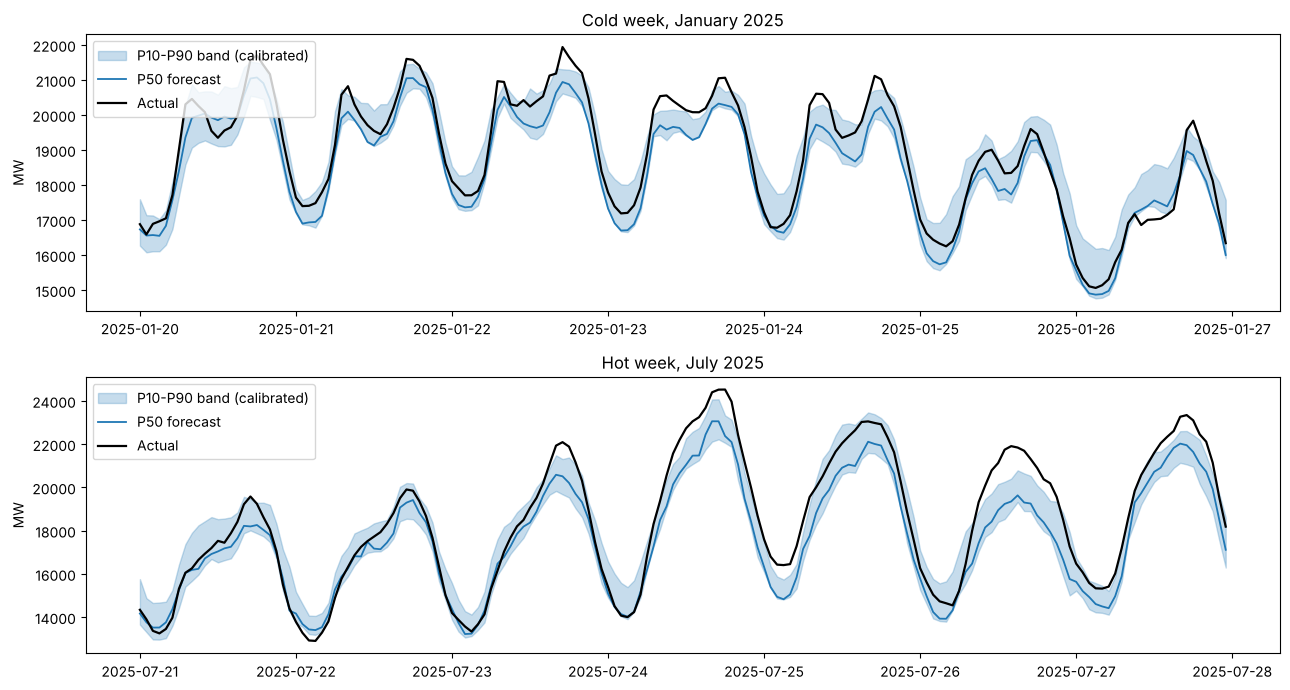

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
for ax, (start, end, title) in zip(axes, [("2025-01-20", "2025-01-26", "Cold week, January 2025"),
                                          ("2025-07-21", "2025-07-27", "Hot week, July 2025")]):
    w = band.loc[start:end]
    ax.fill_between(w.index, w.p10, w.p90, color="#1f77b4", alpha=0.25, label="P10-P90 band (calibrated)")
    ax.plot(w.index, w.p50, color="#1f77b4", lw=1.3, label="P50 forecast")
    ax.plot(w.index, w.y, color="black", lw=1.6, label="Actual")
    ax.set(title=title, ylabel="MW"); ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig("figures/quantile_band_weeks_2025.png", dpi=130)
w = band.loc["2025-07-24"]
print("24 July 2025, 18:00:", w.loc["2025-07-24 18:00", ["y", "p10", "p50", "p90"]].round(0).to_dict())
print("hours of 21-27 July above P90:", int((band.loc["2025-07-21":"2025-07-27"].y > band.loc["2025-07-21":"2025-07-27"].p90).sum()), "of 168")

**What the figure shows**

- **Cold week (20-26 January):** actual demand mostly stays inside the band or close to its upper edge; the evening peaks are often near or just above P90.
- **Hot week (21-27 July):** the band sits too low on the hottest afternoons. On **24 July at 18:00** actual demand was **24,528 MW**, while the band ran from **22,064 to 23,332 MW** (P50 22,377 MW), so demand was about 1,200 MW above P90. In this week **53 of 168 hours** (32%) were above P90, three times the 10% target.
- So the band is honest on ordinary days but does not warn enough about heat-wave afternoons, which are exactly the hours a grid operator worries about.

## 7. The daily peak hours

Planners care most about each day's highest hour. For every day of 2025 we take the hour with the highest actual demand and check whether it fell inside the calibrated band, then repeat for the 20 highest-demand days of the year.

In [7]:
# at each day's actual peak hour: was the peak inside the band?
peak_idx = band.y.groupby(band.index.date).idxmax()
peaks = band.loc[peak_idx.values].copy()
peaks["above_p90"] = peaks.y > peaks.p90
top20 = peaks.nlargest(20, "y")
summary = pd.DataFrame({
    "days": [len(peaks), len(top20)],
    "inside band (%)": [peaks.inside.mean() * 100, top20.inside.mean() * 100],
    "above P90 (%)": [peaks.above_p90.mean() * 100, top20.above_p90.mean() * 100],
    "mean miss above P90 (MW)": [(peaks.y - peaks.p90)[peaks.above_p90].mean(), (top20.y - top20.p90)[top20.above_p90].mean()],
}, index=["All 2025 daily peaks", "20 highest-demand days"]).round(1)
summary

,days,inside band (%),above P90 (%),mean miss above P90 (MW)
All 2025 daily peaks,365,64.4,33.4,451.0
20 highest-demand days,20,25.0,75.0,931.1


**What the table means**

- At the daily peak hour, only **64.4%** of 2025 days are inside the band, and **33.4%** are above P90 (by 451 MW on average when they are). The all-hours coverage of 80% hides a much weaker result at the hour that matters most.
- On the **20 highest-demand days**, actual peak demand was above P90 on **15 of 20 days (75%)**, by 931 MW on average. The band does not cover the top of the year.
- This matches notebooks 05 and 06: the model under-forecasts hot days and the year's highest loads. A band built on that model inherits the same blind spot.

## Takeaways (2025 test year)

- **Raw LightGBM quantile bands are over-confident:** their 80% band held only **64.8%** of 2025 hours, with **28.3%** of hours above P90.
- **A simple conformal correction measured on 2024 fixes the average:** **80.1%** coverage on 2025, with a band **1,320 MW** wide on average. Almost all the correction is on the upper side (P90 +331 MW, P10 +19 MW), which points to load growth, not random noise.
- **The band is weakest where it matters most.** Coverage is 71-75% in the coldest and hottest months, and actual demand was above P90 at the daily peak on **33.4%** of days and on **15 of the 20** highest-demand days.
- **The P50 is a good point forecast:** refitted on 2019-2024 it scores **2.59% MAPE**, slightly better than the 2.63% of the average-based model of notebook 03.

**Next steps:** fix the load-growth bias first (backlog item: trend term or year-over-year target), then calibrate by season or temperature, and re-run this check with the 09:00 cutoff from notebook 07 for a fully realistic band.